#**PROYECTO FINAL DE BIOINFORMATICA**

#Reálisis de datos transcriptómicos mediante herramientas bioinformáticas para el estudio de alteraciones de expresión génica asociadas a tics y síndrome de Tourette.


Maria de la Paz Chagra

Bioinformatica 2026

A partir de la matriz de genes expresados obtenida a travez del analisis bioinformatico en Galaxy se utilizara google colab para hacer un analisis exploratorio y computacional del resultado obtenido.

Ademas se hara una breve comparacion de la matriz publicada en el paper y la generada en galaxy.

#1. Exploracion inicial de la matriz generada por la herramienta salmon en Galaxy Europe

In [4]:
#Cargo librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#Cargo mi matriz de Salmon desde los archivos de Colab
df = pd.read_csv(
    '/content/Matriz_de_expresion.csv.csv',
    sep=','
)

display(df.head())

print("Dimensiones:", df.shape) #Dimensiones de la tabla

print("\nTipos de datos:")
print(df.dtypes) #Tipos de datos

print("\nValores faltantes:", df.isnull().sum().sum()) #Valores faltantes



,Gene_ID,Ticpatient3,Ticpatient17,Ticpatient26,Control1,Control10,Control20
0,ENSG00000000003.18,22.757,31.897,21.669,22.046,14.112,40.070
1,ENSG00000000005.7,0.000,0.000,0.000,0.000,0.000,0.000
2,ENSG00000000419.16,1183.610,1224.810,976.285,1336.350,1073.070,961.767
3,ENSG00000000457.16,1374.150,1244.930,1001.150,1301.960,979.929,923.229
4,ENSG00000000460.19,441.791,362.339,368.966,390.765,311.891,385.936


Dimensiones: (82323, 7)

Tipos de datos:
Gene_ID          object
Ticpatient3     float64
Ticpatient17    float64
Ticpatient26    float64
Control1        float64
Control10       float64
Control20       float64
dtype: object

Valores faltantes: 0


En este primer analisis pudimos verificar las dimensiones de la matriz y los tipos de datos.

La matriz contiene 82.323 indetificadores genicos y 6 columnas correspondientes a muestras biologicas.

Los identificadores estan almacenados como cadenas de texto, mientras que los valores de expresion corresponden a datos numericos tipo float64.

Por ultimo, no se encontraron valores faltantes.

In [5]:
print("\nPrimeras filas:") #Veo las primeras filas de la matriz
display(df.head())

#cantidad de pacientes y cantidad de controles
controles = [col for col in df.columns if col.startswith('Control')]
pacientes = [col for col in df.columns if col.startswith('Ticpatient')]

print("Cantidad de controles:", len(controles))
print("Cantidad de pacientes:", len(pacientes))

#separacion de los valores de expresion: identifica las columnas correspondientes a pacientes y controles
genes = df["Gene_ID"] # df: matriz original cargada con pandas

expresion = df.drop(columns=["Gene_ID"]) # gene id:selecciona la columna que contiene los identificadores de los genes

pacientes = [
    col for col in expresion.columns
    if col.startswith("Ticpatient")
]

controles = [
    col for col in expresion.columns
    if col.startswith("Control")
]

print("Pacientes:", pacientes)
print("Controles:", controles)


Primeras filas:


,Gene_ID,Ticpatient3,Ticpatient17,Ticpatient26,Control1,Control10,Control20
0,ENSG00000000003.18,22.757,31.897,21.669,22.046,14.112,40.070
1,ENSG00000000005.7,0.000,0.000,0.000,0.000,0.000,0.000
2,ENSG00000000419.16,1183.610,1224.810,976.285,1336.350,1073.070,961.767
3,ENSG00000000457.16,1374.150,1244.930,1001.150,1301.960,979.929,923.229
4,ENSG00000000460.19,441.791,362.339,368.966,390.765,311.891,385.936


Cantidad de controles: 3
Cantidad de pacientes: 3
Pacientes: ['Ticpatient3', 'Ticpatient17', 'Ticpatient26']
Controles: ['Control1', 'Control10', 'Control20']


Se pudieron identificar las muestras correspondientesa a los dos grupos experimentales:

- 3 pacientes con tics
- 3 controles sanos

#2. Exploracion inicial de la matriz publicada por el articulo (48 muestras)

In [6]:
#Cargo la matriz del estudio original desde los archivos de Colab
import pandas as pd

matriz_original = pd.read_csv(
    '/content/Datos_genes.csv.csv',
    sep=','
)

display(matriz_original.head())

print("Dimensiones de la matriz original:", matriz_original.shape) #Dimensiones de la tabla

print("\nPrimeras filas:") #Veo las primeras filas de la matriz
display(matriz_original.head())

print("Dimensiones:", matriz_original.shape) #Dimensiones de la tabla

print("\nTipos de datos:")
print(matriz_original.dtypes) #Tipos de datos

print("\nValores faltantes:", matriz_original.isnull().sum().sum()) #Valores faltantes


,Geneid,Control3,Control11,Control4,Control5,Control1,Ticpatient17,Ticpatient8,Ticpatient22,Ticpatient26,...,Ticpatient7,Control17,Ticpatient16,Control15,Ticpatient10,Control13,Ticpatient27,Ticpatient5,Ticpatient13,Control8
0,DDX11L2,64,31,32,29,52,29,43,35,27,...,30,32,43,38,47,154,58,40,62,36
1,MIR1302-2HG,2,2,1,0,0,0,0,0,1,...,0,1,1,1,2,4,0,0,0,0
2,FAM138A,1,0,0,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,1
3,ENSG00000290826,0,0,0,0,0,0,0,0,8,...,0,5,0,0,0,0,0,0,0,0
4,OR4F5,0,0,0,0,0,0,0,0,5,...,0,2,0,0,0,0,0,0,0,0


Dimensiones de la matriz original: (38584, 49)

Primeras filas:


,Geneid,Control3,Control11,Control4,Control5,Control1,Ticpatient17,Ticpatient8,Ticpatient22,Ticpatient26,...,Ticpatient7,Control17,Ticpatient16,Control15,Ticpatient10,Control13,Ticpatient27,Ticpatient5,Ticpatient13,Control8
0,DDX11L2,64,31,32,29,52,29,43,35,27,...,30,32,43,38,47,154,58,40,62,36
1,MIR1302-2HG,2,2,1,0,0,0,0,0,1,...,0,1,1,1,2,4,0,0,0,0
2,FAM138A,1,0,0,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,1
3,ENSG00000290826,0,0,0,0,0,0,0,0,8,...,0,5,0,0,0,0,0,0,0,0
4,OR4F5,0,0,0,0,0,0,0,0,5,...,0,2,0,0,0,0,0,0,0,0


Dimensiones: (38584, 49)

Tipos de datos:
Geneid          object
Control3         int64
Control11        int64
Control4         int64
Control5         int64
Control1         int64
Ticpatient17     int64
Ticpatient8      int64
Ticpatient22     int64
Ticpatient26     int64
Control12        int64
Ticpatient1      int64
Control19        int64
Ticpatient14     int64
Control7         int64
Control6         int64
Ticpatient28     int64
Ticpatient24     int64
Ticpatient2      int64
Control10        int64
Ticpatient6      int64
Ticpatient3      int64
Control9         int64
Ticpatient21     int64
Control14        int64
Control16        int64
Ticpatient18     int64
Ticpatient11     int64
Ticpatient15     int64
Control2         int64
Ticpatient9      int64
Control18        int64
Ticpatient19     int64
Ticpatient25     int64
Ticpatient4      int64
Ticpatient23     int64
Ticpatient20     int64
Control20        int64
Ticpatient12     int64
Ticpatient7      int64
Control17        int64
Ticpatient16   

La matriz original tiene 38584 filas correspondientes a caracteristicas genicas y 49 columnas (48 son las muestras biologicas).

Los valores de expresion son numericosde tipo int64 mientras que los genes estan identificados mediante nombres o codigos genicos.

No se encontraron valores faltantes


In [7]:
print("\nPrimeras filas:") #Veo las primeras filas de la matriz
display(matriz_original.head())

#cantidad de pacientes y cantidad de controles
controles = [col for col in matriz_original.columns if col.startswith('Control')]
pacientes = [col for col in matriz_original.columns if col.startswith('Ticpatient')]

print("Cantidad de controles:", len(controles))
print("Cantidad de pacientes:", len(pacientes))

#separacion de los valores de expresion: identifica las columnas correspondientes a pacientes y controles
genes_original = matriz_original["Geneid"] # matriz_original: matriz del articulo cargada con pandas

expresion_original = matriz_original.drop(columns=["Geneid"]) # Geneid: selecciona la columna que contiene los identificadores de los genes

pacientes_original = [
    col for col in expresion_original.columns
    if col.startswith("Ticpatient")
]

controles_original = [
    col for col in expresion_original.columns
    if col.startswith("Control")
]

print("Pacientes:", pacientes_original)
print("Controles:", controles_original)



Primeras filas:


,Geneid,Control3,Control11,Control4,Control5,Control1,Ticpatient17,Ticpatient8,Ticpatient22,Ticpatient26,...,Ticpatient7,Control17,Ticpatient16,Control15,Ticpatient10,Control13,Ticpatient27,Ticpatient5,Ticpatient13,Control8
0,DDX11L2,64,31,32,29,52,29,43,35,27,...,30,32,43,38,47,154,58,40,62,36
1,MIR1302-2HG,2,2,1,0,0,0,0,0,1,...,0,1,1,1,2,4,0,0,0,0
2,FAM138A,1,0,0,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,1
3,ENSG00000290826,0,0,0,0,0,0,0,0,8,...,0,5,0,0,0,0,0,0,0,0
4,OR4F5,0,0,0,0,0,0,0,0,5,...,0,2,0,0,0,0,0,0,0,0


Cantidad de controles: 20
Cantidad de pacientes: 28
Pacientes: ['Ticpatient17', 'Ticpatient8', 'Ticpatient22', 'Ticpatient26', 'Ticpatient1', 'Ticpatient14', 'Ticpatient28', 'Ticpatient24', 'Ticpatient2', 'Ticpatient6', 'Ticpatient3', 'Ticpatient21', 'Ticpatient18', 'Ticpatient11', 'Ticpatient15', 'Ticpatient9', 'Ticpatient19', 'Ticpatient25', 'Ticpatient4', 'Ticpatient23', 'Ticpatient20', 'Ticpatient12', 'Ticpatient7', 'Ticpatient16', 'Ticpatient10', 'Ticpatient27', 'Ticpatient5', 'Ticpatient13']
Controles: ['Control3', 'Control11', 'Control4', 'Control5', 'Control1', 'Control12', 'Control19', 'Control7', 'Control6', 'Control10', 'Control9', 'Control14', 'Control16', 'Control2', 'Control18', 'Control20', 'Control17', 'Control15', 'Control13', 'Control8']


Se identificaron las muestras de los dos grupos experimentales.
- 28 pacientes con trastornos de tics
- 20 controles sanos

#3. Comparacion de las matrices (sin filtracion o normalizacion)

En esta etapa del proyecto se propone comparar los resultados obtenidos con los datos transcriptomicos publicados por patel et al. (2026)

El objetivo es evaluar la concordancia entre el procesamiento bioinformatico que se hizo en galaxy con el estudio original y ademas investigar como cambia la distribucion de las muestras al utilizar un conjunto de datos mas amplio

In [8]:
#identifico las 6 muestras que yo analice previamente en la matriz original
muestras = [
    "Ticpatient3", "Ticpatient17", "Ticpatient26",
    "Control1", "Control10", "Control20"
]

#verifico si estan presentes
for muestra in muestras:
    print(muestra, ":", muestra in matriz_original.columns)


Ticpatient3 : True
Ticpatient17 : True
Ticpatient26 : True
Control1 : True
Control10 : True
Control20 : True


In [9]:
#Selecciono ls 6 muestras de la matriz original
matriz_original_6 = matriz_original[["Geneid"] + muestras]

# Mostrar las dimensiones de la nueva matriz
print("Dimensiones de la matriz seleccionada:", matriz_original_6.shape)

# Mostrar las primeras filas
print("\nPrimeras filas:")
display(matriz_original_6.head())

Dimensiones de la matriz seleccionada: (38584, 7)

Primeras filas:


,Geneid,Ticpatient3,Ticpatient17,Ticpatient26,Control1,Control10,Control20
0,DDX11L2,42,29,27,52,17,61
1,MIR1302-2HG,2,0,1,0,0,1
2,FAM138A,0,0,0,0,0,1
3,ENSG00000290826,6,0,8,0,0,0
4,OR4F5,7,0,5,0,0,0


Se verifico que los seis individuos procesados previamente estan presentes en la matriz de expresion publicada por los investigadores.

Antes de comparar los valores de expresion, es necesario comprobar como estan identificados los genes en ambas matrices.

Aunque ambas matrices tengan informacion sobre los mismos genes no podemos comparar directamente sus valores si primero no verificamos que los indicadores correspondan al mismo gen.

Por eso lo que se buscara es establecer la correspondencia entre los identificadores genicos de ambas matrices.



In [10]:
#revisar identificadores de genes de ambas matrices
#primeros identificadores de mi matriz
print("Genes de mi matriz:")
print(df["Gene_ID"].head(10))

#primeros identificadores de la matriz original
print("\nGenes de la matriz publicada:")
print(matriz_original_6["Geneid"].head(10))


Genes de mi matriz:
0    ENSG00000000003.18
1     ENSG00000000005.7
2    ENSG00000000419.16
3    ENSG00000000457.16
4    ENSG00000000460.19
5    ENSG00000000938.15
6    ENSG00000000971.19
7    ENSG00000001036.16
8    ENSG00000001084.15
9    ENSG00000001167.17
Name: Gene_ID, dtype: object

Genes de la matriz publicada:
0            DDX11L2
1        MIR1302-2HG
2            FAM138A
3    ENSG00000290826
4              OR4F5
5    ENSG00000238009
6    ENSG00000239945
7    ENSG00000239906
8    ENSG00000241860
9    ENSG00000241599
Name: Geneid, dtype: object


Como las dos matrices utilizan diferentes identificadores, no es posible comparar directamente los valores de expresion.

Para poder hacerlo se eliminaran los numeros de version de Esembl de los identificadores y luego se usara la anotacion GENCODE para relacionarlos con los nombres de genes de la matriz original.

Asi se podra identificar genes presentes en ambas matrices y comparar sus valores de expresion entre los 6 individuos.

In [11]:
#Eliminar numeros de la version de Esembl

#olumna con los identificadores sin version
df["Gene_ID_sin_version"] = df["Gene_ID"].str.split(".").str[0]

# identificadores originales y los modificados
print("Identificadores Ensembl:")
display(df[["Gene_ID", "Gene_ID_sin_version"]].head(10))

Identificadores Ensembl:


,Gene_ID,Gene_ID_sin_version
0,ENSG00000000003.18,ENSG00000000003
1,ENSG00000000005.7,ENSG00000000005
2,ENSG00000000419.16,ENSG00000000419
3,ENSG00000000457.16,ENSG00000000457
4,ENSG00000000460.19,ENSG00000000460
5,ENSG00000000938.15,ENSG00000000938
6,ENSG00000000971.19,ENSG00000000971
7,ENSG00000001036.16,ENSG00000001036
8,ENSG00000001084.15,ENSG00000001084
9,ENSG00000001167.17,ENSG00000001167


In [12]:
#Busco identificadores coincidentes entreambas matrices
coincidencias = df["Gene_ID_sin_version"].isin(matriz_original_6["Geneid"])

#Cuantos identificadores coinciden
print("Genes con identificadores coincidentes:", coincidencias.sum())

#ejemplos de coincidencias
print("\nEjemplos de genes coincidentes:")
display(df.loc[coincidencias, ["Gene_ID", "Gene_ID_sin_version"]].head(10))


Genes con identificadores coincidentes: 11960

Ejemplos de genes coincidentes:


,Gene_ID,Gene_ID_sin_version
1598,ENSG00000083622.8,ENSG00000083622
5596,ENSG00000124835.2,ENSG00000124835
8656,ENSG00000145063.16,ENSG00000145063
12005,ENSG00000167046.4,ENSG00000167046
12904,ENSG00000170846.17,ENSG00000170846
13588,ENSG00000173862.4,ENSG00000173862
13640,ENSG00000174171.8,ENSG00000174171
13913,ENSG00000175604.2,ENSG00000175604
14052,ENSG00000176320.3,ENSG00000176320
14055,ENSG00000176349.12,ENSG00000176349


Se encontraron 11960 coincidencias directas, lo que permitio identificar un conjunto de genes que pueden relacionarse entre ambos analisis.

Este resultado no representa necesariamente la totalidad de los genes compartidos ya que la matriz original usa tanto identificadores de Esembl como simbolos genicos.

Por este motivo se usara la anotacion GENCODE para establecer una correspondencia mas completa entre los identificadores de ambas matrices para comparar sus niveles de expresion.

Para esta parte del proceso se usara el archivo de GENCODE:

gencode.v50.chr_patch_hapl_scaff.annotation.gtf.gz

que se uso previamente en galaxy para la cuantizacion de los mismos

In [13]:
#Descargar archivo de anotacion gencode
import os

url = "https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_50/gencode.v50.chr_patch_hapl_scaff.annotation.gtf.gz"

#Guardar el archivo en los archivos de Colab
archivo_gtf = "/content/gencode.v50.chr_patch_hapl_scaff.annotation.gtf.gz"

#Descargar el archivo
import urllib.request

#Solo descargar si todavia no esta cargado
if not os.path.exists(archivo_gtf):
    urllib.request.urlretrieve(url, archivo_gtf)

#Comprobar
print("¿Se encontro el archivo?", os.path.exists(archivo_gtf))


¿Se encontro el archivo? True


In [14]:
#obtener los identificadores y nombres de genes desde gencode

import gzip
import pandas as pd
import re

#lista para guardar los genes
lista_genes = []

# Abro el archivo GENCODE comprimido
with gzip.open(archivo_gtf, "rt") as archivo:

    #recorro archivo
    for linea in archivo:
        if linea.startswith("#"): #para ignorar comentarios
            continue

        #separo columnas del archivo GTF
        columnas = linea.strip().split("\t")

        #seleccion solo de registros correspondientes a genes
        if len(columnas) == 9 and columnas[2] == "gene":

            #Busco identificador de Ensembl y nombre del gen
            id_gen = re.search(r'gene_id "([^"]+)"', columnas[8])
            nombre_gen = re.search(r'gene_name "([^"]+)"', columnas[8])

            if id_gen and nombre_gen:
                identificador = id_gen.group(1).split(".")[0] #elimino num de version
                lista_genes.append([identificador, nombre_gen.group(1)]) #Guardo identificador y su nombre


#Tabla con resultados
anotacion_genes = pd.DataFrame(
    lista_genes,
    columns=["Gene_ID_sin_version", "Gene_name"]
)

#Muestro dimensiones y primeras filas
print("Dimensiones de la tabla de anotación:", anotacion_genes.shape)
display(anotacion_genes.head())

Dimensiones de la tabla de anotación: (86411, 2)


,Gene_ID_sin_version,Gene_name
0,ENSG00000290825,DDX11L16
1,ENSG00000223972,DDX11L1
2,ENSG00000310526,WASH7P
3,ENSG00000227232,WASH7P
4,ENSG00000278267,MIR6859-1


Se obtuvo una tabla de 86411 registros y dos columnas. Esto permitira relacionar genes de la matriz generada en galaxy con los de la matriz publicada.

Algunos simbolos genicos aparecen asociados a diferentes identificadores Ensembl por lo que hay que verificarlas antes de hacer la comparacion.

In [15]:
#Comprobar identificadores y nombres de genes repetidos

#cuento duplicados
print("Identificadores Ensembl duplicados:",
      anotacion_genes["Gene_ID_sin_version"].duplicated().sum())

#cuento simbolos genicos repetidos
print("Símbolos génicos duplicados:",
      anotacion_genes["Gene_name"].duplicated().sum())

#ejemplos
print("\nEjemplos de símbolos génicos repetidos:")
display(
    anotacion_genes[
        anotacion_genes["Gene_name"].duplicated(keep=False)
    ].head(10)
)

Identificadores Ensembl duplicados: 0
Símbolos génicos duplicados: 7272

Ejemplos de símbolos génicos repetidos:


,Gene_ID_sin_version,Gene_name
0,ENSG00000290825,DDX11L16
2,ENSG00000310526,WASH7P
3,ENSG00000227232,WASH7P
24,ENSG00000308415,DDX11L2
25,ENSG00000310527,WASH9P
27,ENSG00000279457,WASH9P
43,ENSG00000278757,U6
204,ENSG00000149527,PLCH2
207,ENSG00000157881,PANK4
208,ENSG00000197921,HES5


No se encontraron identificadores Ensembl duplicados, sin embargo se identificaron 7272 repeticiones adicionales de simbolos genicos.

Por eso solo se consideraran correspondencias no ambiguas ente identificadores y simbolos genicos.

In [16]:
#Seleccion de genes con simbolos no ambiguos

#Simbolos que aparecen una sola vez
simbolos_unicos = ~anotacion_genes["Gene_name"].duplicated(keep=False)

#tabla con las correspondencias no ambiguas
anotacion_unica = anotacion_genes.loc[simbolos_unicos].copy()

# Muestro las dimensiones
print("Dimensiones de la anotación original:", anotacion_genes.shape)
print("Dimensiones de la anotación sin símbolos repetidos:", anotacion_unica.shape)

# Muestro las primeras filas
display(anotacion_unica.head())

Dimensiones de la anotación original: (86411, 2)
Dimensiones de la anotación sin símbolos repetidos: (75755, 2)


,Gene_ID_sin_version,Gene_name
1,ENSG00000223972,DDX11L1
4,ENSG00000278267,MIR6859-1
5,ENSG00000243485,MIR1302-2HG
6,ENSG00000284332,MIR1302-2
7,ENSG00000237613,FAM138A


Se obtuvo una tabla donde cada simbolo genico aparece asociado a un unico identificadore Ensembl.

- 75.755 correspondencias no ambiguas
- 10.656 registros que pertenecían a símbolos repetidos.

In [18]:
#Agregar los nombres de genes a la matriz hecha con galaxy
# Unir matriz con tabla de anotacion
matriz_salmon_anotada = pd.merge(
    df,
    anotacion_unica,
    on="Gene_ID_sin_version",
    how="left",
    validate="one_to_one"
)

# Compruebo las dimensiones
print("Dimensiones de mi matriz:", df.shape)
print("Dimensiones de la matriz publicada:", matriz_salmon_anotada.shape)

# Cuento los genes a los que se pudo asignar un nombre
print("Genes con nombre asignado:",
      matriz_salmon_anotada["Gene_name"].notna().sum())

# Muestro las primeras filas
display(matriz_salmon_anotada.head())


Dimensiones de mi matriz: (82323, 8)
Dimensiones de la matriz publicada: (82323, 9)
Genes con nombre asignado: 74423


,Gene_ID,Ticpatient3,Ticpatient17,Ticpatient26,Control1,Control10,Control20,Gene_ID_sin_version,Gene_name
0,ENSG00000000003.18,22.757,31.897,21.669,22.046,14.112,40.070,ENSG00000000003,TSPAN6
1,ENSG00000000005.7,0.000,0.000,0.000,0.000,0.000,0.000,ENSG00000000005,TNMD
2,ENSG00000000419.16,1183.610,1224.810,976.285,1336.350,1073.070,961.767,ENSG00000000419,DPM1
3,ENSG00000000457.16,1374.150,1244.930,1001.150,1301.960,979.929,923.229,ENSG00000000457,SCYL3
4,ENSG00000000460.19,441.791,362.339,368.966,390.765,311.891,385.936,ENSG00000000460,FIRRM


- Genes totales	82.323
- Genes con nombre asignado	74.423
- Genes sin correspondencia en la anotación filtrada	7.900

In [19]:
#Buscar genes compartidos entre las dos matrices

#Que simbolos aparecen en la matri original
genes_compartidos = matriz_salmon_anotada["Gene_name"].isin(
    matriz_original_6["Geneid"]
)

# Cuento las coincidencias
print("Genes compartidos:", genes_compartidos.sum())

#ejemplos
print("\nEjemplos de genes compartidos:")
display(
    matriz_salmon_anotada.loc[
        genes_compartidos,
        ["Gene_ID", "Gene_name"]
    ].head(10)
)


Genes compartidos: 34213

Ejemplos de genes compartidos:


,Gene_ID,Gene_name
0,ENSG00000000003.18,TSPAN6
1,ENSG00000000005.7,TNMD
2,ENSG00000000419.16,DPM1
3,ENSG00000000457.16,SCYL3
5,ENSG00000000938.15,FGR
6,ENSG00000000971.19,CFH
7,ENSG00000001036.16,FUCA2
8,ENSG00000001084.15,GCLC
9,ENSG00000001167.17,NFYA
10,ENSG00000001460.20,STPG1


se encontraron 34.213 coincidencias, lo que indica que una parte importante de los genes cuantificados en galaxy tambien esta representada en los datos del estudio original.

 Antes de comparar los niveles de expresion hay q verificar que cada simbolo utilizado identifique una unica fila en ambas matrices, evitando duplicados.

In [20]:
#Comprobar genes repetidos en la matriz original

#Cuantos identificadores estan repetidos
print("Identificadores duplicados en la matriz original:",
      matriz_original_6["Geneid"].duplicated().sum())

#ejemplos
print("\nEjemplos de identificadores duplicados:")
display(
    matriz_original_6[
        matriz_original_6["Geneid"].duplicated(keep=False)
    ].head(10)
)

Identificadores duplicados en la matriz original: 0

Ejemplos de identificadores duplicados:


,Geneid,Ticpatient3,Ticpatient17,Ticpatient26,Control1,Control10,Control20


No se encontraron duplicados en la columna Geneid.

Ahora si se puede unir ambas matrices con sus genes compartidos.

In [21]:
#Unir las matrices por los genes compartidos

#Selecciono los genes compartidos de mi matriz
salmon_compartidos = matriz_salmon_anotada.loc[
    genes_compartidos,
    ["Gene_name"] + muestras
]

#Uno ambas matrices utilizando el nombre del gen
matriz_comparacion = pd.merge(
    salmon_compartidos,
    matriz_original_6,
    left_on="Gene_name",
    right_on="Geneid",
    how="inner",
    suffixes=("_Salmon", "_Original"),
    validate="one_to_one"
)

#Muestro las dimensiones
print("Dimensiones de la matriz de comparación:", matriz_comparacion.shape)

#Muestro las primeras filas
display(matriz_comparacion.head())


Dimensiones de la matriz de comparación: (34213, 14)


,Gene_name,Ticpatient3_Salmon,Ticpatient17_Salmon,Ticpatient26_Salmon,Control1_Salmon,Control10_Salmon,Control20_Salmon,Geneid,Ticpatient3_Original,Ticpatient17_Original,Ticpatient26_Original,Control1_Original,Control10_Original,Control20_Original
0,TSPAN6,22.757,31.897,21.669,22.046,14.112,40.070,TSPAN6,3,8,8,8,8,11
1,TNMD,0.000,0.000,0.000,0.000,0.000,0.000,TNMD,0,1,0,0,0,0
2,DPM1,1183.610,1224.810,976.285,1336.350,1073.070,961.767,DPM1,742,687,852,947,794,678
3,SCYL3,1374.150,1244.930,1001.150,1301.960,979.929,923.229,SCYL3,698,521,603,688,544,475
4,FGR,10328.500,5020.690,8563.890,6843.080,6918.760,8240.460,FGR,6796,5467,3675,5036,5113,5625


Se obtuvo una matriz de comparacion con 34.213 genes y 14 columnas, que corresponden a los identificadoes genicos y los valores de expresion de los 6 individuos obtenidos mediante ambos procesamientos bioinformaticos.

Se observaron diferencias en los conteos de algunos genes entre ambas matrices.

Estas diferencias pueden estar relacionadas con los distintos métodos de cuantificación utilizados.

Comparacion final de las dos matrices

Se calculara una correlacion para cada uno de los seis individuos comparando sus 34.213 valores de expresion entre ambos procesamientos.

El resultado sera un numero entre -1 y +1. Si la correlacion:

- cercana a +1: los genes mantienen un orden de expresion parecido
- cercana a 0: no existe tendencia clara de concordancia
- cercana a -1: los genes presentan un orden de expresion inverso



In [22]:
#Comparar la similitud entre las matrices

#Creo una lista para guardar las correlaciones
correlaciones = []

#Recorro las seis muestras
for muestra in muestras:

    #Selecciono los valores de las dos matrices
    salmon = matriz_comparacion[muestra + "_Salmon"]
    original = matriz_comparacion[muestra + "_Original"]

    #Calculo la correlación de Spearman
    correlacion = salmon.corr(original, method="spearman")

    #Guardo el nombre de la muestra y su resultado
    correlaciones.append([muestra, correlacion])

#Creo una tabla con los resultados
df_correlaciones = pd.DataFrame(
    correlaciones,
    columns=["Muestra", "Correlacion"]
)

#Muestro los resultados
print("Correlación entre las matrices:")
display(df_correlaciones.round(3))


Correlación entre las matrices:


,Muestra,Correlacion
0,Ticpatient3,0.861
1,Ticpatient17,0.846
2,Ticpatient26,0.851
3,Control1,0.861
4,Control10,0.857
5,Control20,0.862


La correlacion promedio de las seis muestras es 0.856.

Esto significa que los genes que tienen mayor expresion en la matriz generada en galaxy tambien presentan mayor expresion en la matriz publicada.

Ademas, las 6 muestras tienen correlaciones muy similares (entre 0,846 y 0,862)aun usando herramientas distintas de cuantificacion.

Sin embargo, una correlacion elevada no significa que los conteos sean iguales, sino que los genes mantienen un orden de abundancia parecido

#4. Analisis exploratorio de los perfiles de expresion genica.

En esta etapa se realizaran analisis de componentes principales (PCA) y agrupamiento mediante K-means para explorar las similitudes y diferencias entre los perfiles de expresion genica de pacientes con trastornos de tics y controles sanos.

El objetivo es observar si los individuos tienden a agruparse segun su condicion y comparar si los patrones de agrupamiento cambian al utilizar una mayor cantidad de muestras.

#- Analisis de las 6 muestras (mi matriz): PCA y K-means

In [23]:
#busco genes con expresion cero
genes_sin_expresion = (expresion == 0).all(axis=1)

print("Genes con cero en todas las muestras:")
print(genes_sin_expresion.sum())

print("\nGenes detectados en al menos una muestra:")
print((~genes_sin_expresion).sum())

Genes con cero en todas las muestras:
37059

Genes detectados en al menos una muestra:
45264


Se evaluo la precencia de genes sin expresion detectable, siendo 37.059 genes con valores iguales a cero en las 6 muestras y los 45264 restantes persentaron una expresion el al menos una muestra

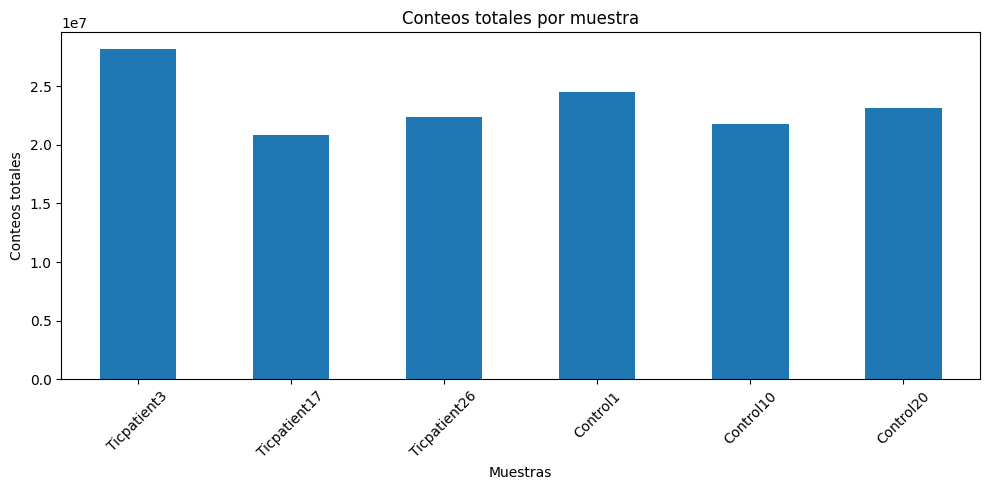

In [24]:
#grafico los totales por muestra
totales = expresion.sum(axis=0)

plt.figure(figsize=(10, 5))

totales.plot(kind="bar")

plt.title("Conteos totales por muestra")
plt.xlabel("Muestras")
plt.ylabel("Conteos totales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Se calcularon y representaron graficamente los conteos totales estimados por muestra. Podemos ver difrencias en la cantidad total de los fragmentos asignados a cada una por lo es necesario hacer una normalizacion de los datos antes de hacer comparaciones de expresion genica.

Filtrado de datos

In [25]:
# Filtracion de genes con expresion cero en todas las muestras

expresion_filtrada = expresion.loc[~genes_sin_expresion]
#~ : invierte valores booleanos y permite seleccionar los genes con expresion en al menos 1 muestra
#loc[]: selecciona filas q cumplen la condicion

print("Dimensiones originales:", expresion.shape)
print("Dimensiones filtradas:", expresion_filtrada.shape)

Dimensiones originales: (82323, 6)
Dimensiones filtradas: (45264, 6)


A partir del analisis exploratorio de la matriz se encontraron 37059 genes con valores de expresion iguales a cero en las 6 muestras.

Se utilizio este filtrado con el fin de "eliminarlos" ya que no aportant variabilidad al conjunto de datos y no contribuyen a la diferenciacion de los niveles de expresion.

Como resultado se obtuvo una nueva matriz de 45264 genes y seis muestras pero conservando la matriz original.

Los valores de la matriz resultante corresponden a NumReads, obtenidos mediante salmon durante el procesamiento de los datos en galaxy. Estos valores no son comparables porque cada musyra puede tener una cantidad diferente de lecturas secuenciadas.

Por esta razon se hara una normalizacion,que permite reducir las diferencias entre muestras para poder compararlas y una transformacion, que permite reducir la influencia de los genes con valores de expresion muy elevados facilitando el analisis de los datos.





Normalizacion y transformacion de los datos

In [26]:
#Primero se calculan los conteos totales de cada muestra
#Cada columna representa una muetsra y contiene los conteos
#estimados de todos los genes que se conservaron despues del filtrado

#axis=0 --> sumamos los valores de cada columna
totales = expresion_filtrada.sum(axis=0)

# Mostrar los resultados.
print("Conteos totales por muestra:")
print(totales)

Conteos totales por muestra:
Ticpatient3     2.817363e+07
Ticpatient17    2.081334e+07
Ticpatient26    2.239356e+07
Control1        2.450659e+07
Control10       2.178834e+07
Control20       2.313333e+07
dtype: float64


Los resultados muestran que TicPatient3 presenta el mayor numero de conteos estimados mientras que TicPatient17 el menor

In [27]:
#Normalizacion de los datos mediante CPM (counts per million)
#Formula: CPMij= Cij/Nj x 10^6
expresion_cpm = expresion_filtrada.div(totales, axis=1) * 1000000

# Mostrar las primeras cinco filas de la matriz normalizada.
print("Matriz normalizada mediante CPM:")
display(expresion_cpm.head())


Matriz normalizada mediante CPM:


,Ticpatient3,Ticpatient17,Ticpatient26,Control1,Control10,Control20
0,0.807741,1.532526,0.967644,0.899595,0.647686,1.732133
2,42.011275,58.847344,43.596685,54.530220,49.249747,41.574945
3,48.774337,59.814031,44.707049,53.126924,44.974937,39.909037
4,15.681012,17.408976,16.476433,15.945300,14.314586,16.683113
5,366.601709,241.224573,382.426461,279.234224,317.544226,356.215869


En esta nueva matriz los valores representan conteos estimados por millon en vez de conteos originales.

Se puede ver algunas diferencias en los niveles de expresion de un mismo gen en las primeras filas

In [28]:
#Transformacion de los calores medinate log2(CPM + 1)
#Se suma 1 porque algunos genes todavia pueden tener CPM igual a cero.
expresion_log = np.log2(expresion_cpm + 1)

# Mostrar las primeras cinco filas.
print("Matriz transformada:")
display(expresion_log.head())

Matriz transformada:


,Ticpatient3,Ticpatient17,Ticpatient26,Control1,Control10,Control20
0,0.854188,1.340577,0.976469,0.925692,0.720441,1.450028
2,5.426643,5.903215,5.478865,5.795201,5.651044,5.411933
3,5.637330,5.926332,5.514345,5.758274,5.522776,5.354348
4,4.060135,4.202337,4.127339,4.082813,3.936834,4.144300
5,8.522000,7.920201,8.582806,8.130489,8.315350,8.480652


Podemos ver que al aplicar la transofrmacion los valores que estaban elevados disminuyeron notoriamente, mientras que los valores bajos conservaron una menor escala.

In [29]:
#Comprobar dimensiones y valores de la matriz
#Verifico que la normalizacion y la transformacion no haya eliminado, muestras, genes ni agregado valores faltantes
# Comprobar las dimensiones de la matriz.
print("Dimensiones:", expresion_log.shape)

# Comprobar si existen valores faltantes.
print("Valores faltantes:", expresion_log.isnull().sum().sum())

# Comprobar si todos los valores son finitos.
print("Todos los valores son finitos:",
      np.isfinite(expresion_log.to_numpy()).all())

# Mostrar algunas filas de la matriz final.
display(expresion_log.head())

Dimensiones: (45264, 6)
Valores faltantes: 0
Todos los valores son finitos: True


,Ticpatient3,Ticpatient17,Ticpatient26,Control1,Control10,Control20
0,0.854188,1.340577,0.976469,0.925692,0.720441,1.450028
2,5.426643,5.903215,5.478865,5.795201,5.651044,5.411933
3,5.637330,5.926332,5.514345,5.758274,5.522776,5.354348
4,4.060135,4.202337,4.127339,4.082813,3.936834,4.144300
5,8.522000,7.920201,8.582806,8.130489,8.315350,8.480652


Se conservaron correctamente los seis individuos y genes filtrados


Analisis de componentes principales (PCA)

El PCA permite representar un conjunto de datos con muchas variables mediante un numero reducido de componentes principales

En este proyecto hay 45264 genes y 6 individuos por lo que es dificil visualizar directamente las diferencias de sus perfiles de expresion.

El objetivo es explorar si los pacientes con trastornos de tics y los controles sanos tienen perfiles de expresion parecidos o diferentes

In [30]:
#Preparacion de la matriz para PCA
#FILAS --> individuos
#COLIMNAS --> genes
#Para aplicar PCA cada fila tiene que representar un indivuo y cada columna un gen
matriz_pca = expresion_log.T

# Verificar las dimensiones de la nueva matriz.
print("Dimensiones de la matriz para PCA:", matriz_pca.shape)

# Mostrar las primeras filas y columnas.
display(matriz_pca.iloc[:6, :5])


Dimensiones de la matriz para PCA: (6, 45264)


,0,2,3,4,5
Ticpatient3,0.854188,5.426643,5.637330,4.060135,8.522000
Ticpatient17,1.340577,5.903215,5.926332,4.202337,7.920201
Ticpatient26,0.976469,5.478865,5.514345,4.127339,8.582806
Control1,0.925692,5.795201,5.758274,4.082813,8.130489
Control10,0.720441,5.651044,5.522776,3.936834,8.315350
Control20,1.450028,5.411933,5.354348,4.144300,8.480652


In [31]:
#Calculo de componentes principales
#PCA busca combinaciones de genes que explican variabilidad entre seis muestras
#PC1: direccion de mayor variabilidad
#PC2: segunda direccion de mayor variabilidad independiente de PC1
from sklearn.decomposition import PCA

#Crear el modelo de PCA con dos componentes principales
pca = PCA(n_components=2)

#Calcular los componentes principales
componentes = pca.fit_transform(matriz_pca)

#Mostrar las coordenadas de cada individuo
print("Componentes principales:")
print(componentes)

#Mostrar el porcentaje de variabilidad explicada
print("\nVarianza explicada (%):")
print(pca.explained_variance_ratio_ * 100)

Componentes principales:
[[-28.60661068  23.83201356]
 [-52.24173995 -17.47002851]
 [ 42.27263188  45.07577936]
 [-15.15057434  12.31599747]
 [  6.19075609 -26.14067211]
 [ 47.535537   -37.61308976]]

Varianza explicada (%):
[31.63965177 20.74466535]


Estas son las coordanadas de cada individuo en el grafico de PCA.

PC1 explico el 31,64% de la variabilidad total y PC2 el 20,74% representando conjuntamente el 52,38% de la variabilidad de los datos

In [32]:
#Tabla con los datos de PCA
#Para organizar los datos en un Dataframe
#Dataframe con las coordenadas PC1 y PC2
df_pca = pd.DataFrame(
    componentes,
    columns=["PC1", "PC2"],
    index=matriz_pca.index
)

# Agregar el grupo al que pertenece cada muestra
df_pca["Grupo"] = [
    "Paciente" if muestra.startswith("Ticpatient") else "Control"
    for muestra in df_pca.index
]

# Mostrar la tabla
display(df_pca)

,PC1,PC2,Grupo
Ticpatient3,-28.606611,23.832014,Paciente
Ticpatient17,-52.241740,-17.470029,Paciente
Ticpatient26,42.272632,45.075779,Paciente
Control1,-15.150574,12.315997,Control
Control10,6.190756,-26.140672,Control
Control20,47.535537,-37.613090,Control


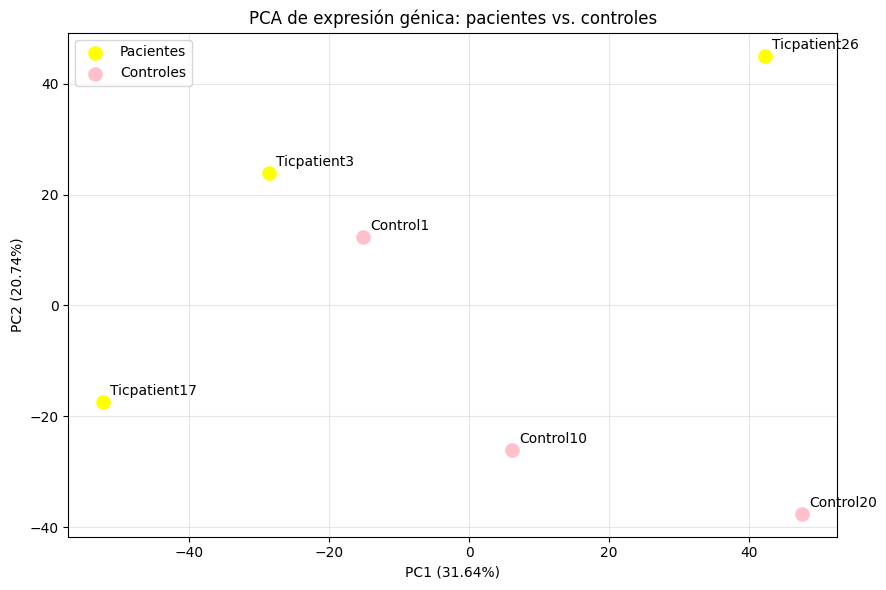

In [33]:
#Grafico de PCA

#Creo la figura
plt.figure(figsize=(9, 6))

#Grafico de los pacientes
plt.scatter(
    df_pca[df_pca["Grupo"] == "Paciente"]["PC1"],
    df_pca[df_pca["Grupo"] == "Paciente"]["PC2"],
    color="yellow",
    label="Pacientes",
    s=90
)

#Grafico de los controles
plt.scatter(
    df_pca[df_pca["Grupo"] == "Control"]["PC1"],
    df_pca[df_pca["Grupo"] == "Control"]["PC2"],
    color="pink",
    label="Controles",
    s=90
)

#Nombre de cada muestra junto a su punto
for muestra in df_pca.index:
    plt.annotate(
        muestra,
        (df_pca.loc[muestra, "PC1"], df_pca.loc[muestra, "PC2"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

#Ejes con nombre porcentajes de varianza
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}%)")

#Titulo, referencias,cuadricula
plt.title("PCA de expresión génica: pacientes vs. controles")
plt.legend()
plt.grid(alpha=0.3)

#Muestro el grafico
plt.tight_layout()
plt.show()


En el grafico se observa una dispersion de muestras y una separacion parcial entre pacientes y controles.

Principalmente sobre PC2 donde los pacientes tienen coordenadas superiores a loscontroles.

De todas formas, los individuos de un musmo grupo no forman agrupamientos compactos y existe proximidad entre muestras como tcpatient3 y control1.

Debido al reducido numero de muestras esta separacion se tiene que interpretar de manera exploratoria y no permite establecer diferencias estadisticamente significativas entre ambos grupos.

Clustering: K-means

El clustering es una tecnica de supervisaje no supervisado que permite agrupar muestras segun sus siilitudes sin usar previamente etiquetas correspondientes a cada grupo experimental.

En este proyecto se busca analizar si los 6 individuos tienen perfiles de expresion genica similares y si los agrupamientos obtenidos coinciden con la clasificacion de pacientes con trastornos de tics y controles sanos

Para esto, se usara el algoritmo k-means.

Con este analisis se busca complemenrar los resultados obtenidos mediante PCA y explorar la existencia de patrones en los tados transcriptomicos.

In [34]:
#Aplicacion de K-means
#se utiliza k=2, es decir, 2 grupos
#K-means solo analiza los valores de expresion para formar dos grupos, aunque estos no existan de manera natural
#Importo k-means desde scijit-learn
from sklearn.cluster import KMeans

#Modelo para los dos grupos
kmeans = KMeans(
    n_clusters=2,
    random_state=0,
    n_init=10
)

#Aplico k-means a la matriz de expresion
grupos_kmeans = kmeans.fit_predict(matriz_pca)#uso la matriz del pca porque ya tiene las filas y las columnas ordenadas

#Mostrar grupo asignado a cada individuo
for muestra, grupo in zip(matriz_pca.index, grupos_kmeans):
    print(muestra, "-> Grupo", grupo)



Ticpatient3 -> Grupo 0
Ticpatient17 -> Grupo 0
Ticpatient26 -> Grupo 1
Control1 -> Grupo 0
Control10 -> Grupo 1
Control20 -> Grupo 1


Como resultado el algoritmo genero dos grupos, el primero integrado por dos pacientes y un control y el segundo por dos controles y un paciente.

Se logro una coincidencia parcial entre agurpamientos obtenidos pero no se logro una separacion completa.


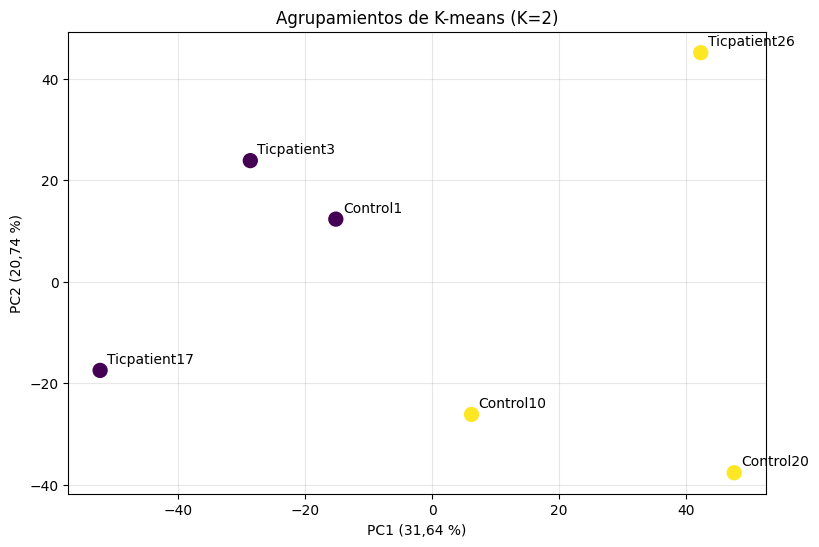

In [35]:
#Graficode agrupamiento de k-means
#creo la figura
plt.figure(figsize=(9, 6))

# Dibujo de losindividuos segun el grupo asignado por kmeans
plt.scatter(
    componentes[:, 0],       # Coordenadas de PC1
    componentes[:, 1],       # Coordenadas de PC2
    c=grupos_kmeans,         # Colores segun los grupos de k-means
    cmap="viridis",          # Escala de colores
    s=100
)

#agregar nombres
for i, muestra in enumerate(matriz_pca.index):
    plt.annotate(
        muestra,
        (componentes[i, 0], componentes[i, 1]),
        xytext=(5, 5),
        textcoords="offset points"
    )

#ejes
plt.xlabel("PC1 (31,64 %)")
plt.ylabel("PC2 (20,74 %)")

#Titulo y cuadricula
plt.title("Agrupamientos de K-means (K=2)")
plt.grid(alpha=0.3)

#Muestro el grafico
plt.show()



Al comparar ambos analisis podemos ver q las muestras ticpatient 3 y control1 presentaban posiciones relativamente cercanas en pca, fueron asignadas por el mismo grupo en k-means. Sin embargo Ticpatient26 fue agrupada junto con Control10 y Control20, a pesar de encontrarse alejada de estos individuos sobre el segundo componente principal.

Esta diferencia se debe a que el grafico de PCA representa unicamente los dos primeros componentes principales, mientras que k-means usa informacion de los mismos genes inclidos en la matriz.

Distancia euclidiana

Para poder conocere que tan diferentes son los perfiles de expresion, utilizaremos la distancia euclidiana entre los 6 individuos usando 45265 genes.

- mayor distancia: perfiles transcriptomicos diferentes
- menor distancia: perfiles transcriptomicos parecidos

In [36]:
#Calculo distancias entre individuos
#importo herramienta
from sklearn.metrics import pairwise_distances

#Calculo distancias
distancias = pairwise_distances(
    matriz_pca,
    metric="euclidean"
)

#Tabla con resultados
df_distancias = pd.DataFrame(
    distancias,
    index=matriz_pca.index,
    columns=matriz_pca.index
)

#muestro
display(df_distancias.round(2))


,Ticpatient3,Ticpatient17,Ticpatient26,Control1,Control10,Control20
Ticpatient3,0.00,96.26,105.31,90.62,95.72,108.33
Ticpatient17,96.26,0.00,115.07,92.42,96.97,114.48
Ticpatient26,105.31,115.07,0.00,97.54,98.10,97.73
Control1,90.62,92.42,97.54,0.00,89.23,101.84
Control10,95.72,96.97,98.10,89.23,0.00,91.15
Control20,108.33,114.48,97.73,101.84,91.15,0.00


Podemos ver que la menor distancia se observo entre Control1 y Control10 (89.23), lo que indica que estos controles presentan perfiles transcriptomicos mas similares dentro del grupo analizado.

Tambien se identifico una distancia relativamente pequena entre Ticpatient3 y Control1(90.62), loq ue coincidde con la proximidad que se pudo ver en el PCA.

Por otra parte la mayor distancia se encontro entre Ticpatient17 y Ticpatient26(115.07) a pesar de que ambos pertenecen al mismo grupo.

Estos resultados muestran la existencia de variabilidad transcriptomica tanto entre individuos de diferentes condiciones como dentro del mismo grupo experimiental.

#- Analisis en la matriz publicada (48 muestras): PCA y K-means

In [37]:
#Busco genes con expresion cero en la matriz original
genes_sin_expresion_original = (expresion_original == 0).all(axis=1)

print("Genes con cero en todas las muestras:")
print(genes_sin_expresion_original.sum())

print("\nGenes detectados en al menos una muestra:")
print((~genes_sin_expresion_original).sum())


Genes con cero en todas las muestras:
4418

Genes detectados en al menos una muestra:
34166


Se identificaron 4.418 genes con expresión igual a cero en las 48 muestras

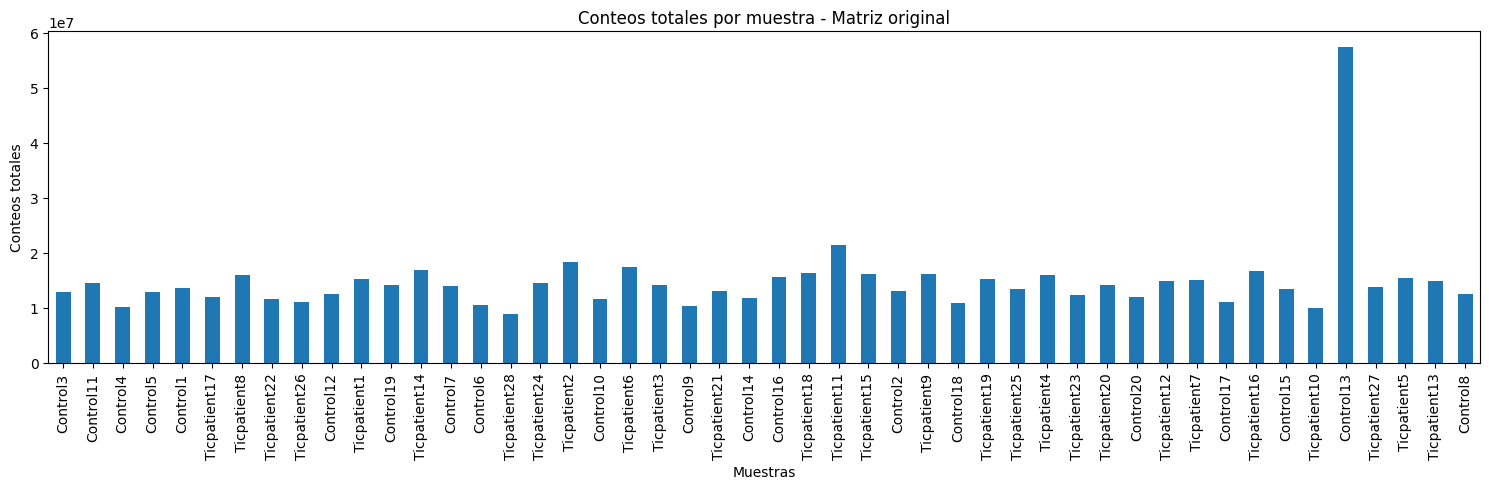

In [38]:
#Grafico los totales por muestra de la matriz original
totales_original = expresion_original.sum(axis=0)

plt.figure(figsize=(15, 5))

totales_original.plot(kind="bar")

plt.title("Conteos totales por muestra - Matriz original")
plt.xlabel("Muestras")
plt.ylabel("Conteos totales")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


Se observaron diferencias en los conteos totales entre las muestras.  Control13 presenta un valor considerablemente mayor que el resto.

Por lo tanto es necesario normalizar los datos antes de realizar los análisis.

In [39]:
#Filtracion de genes con expresion cero en todas las muestras

expresion_filtrada_original = expresion_original.loc[~genes_sin_expresion_original]

#~ : invierte valores booleanos y permite seleccionar los genes con expresion en al menos 1 muestra
#loc[]: selecciona filas q cumplen la condicion

print("Dimensiones originales:", expresion_original.shape)
print("Dimensiones filtradas:", expresion_filtrada_original.shape)


Dimensiones originales: (38584, 48)
Dimensiones filtradas: (34166, 48)


Se eliminaron los 4.418 genes que presentaban conteos iguales a cero en todas las muestras, ya que no aportaban variabilidad al análisis. Se obtuvo una matriz filtrada de 34.166 genes y 48 individuos.

In [40]:
#Primero se calculan los conteos totales de cada muestra
#Cada columna representa una muestra y contiene los conteos
#de todos los genes que se conservaron despues del filtrado

#axis=0 --> sumamos los valores de cada columna
totales_filtrados_original = expresion_filtrada_original.sum(axis=0)

#Mostrar los resultados
print("Conteos totales por muestra:")
print(totales_filtrados_original)


Conteos totales por muestra:
Control3        12792988
Control11       14408345
Control4        10161994
Control5        12845149
Control1        13517921
Ticpatient17    11986324
Ticpatient8     15976860
Ticpatient22    11625596
Ticpatient26    10977356
Control12       12543624
Ticpatient1     15169417
Control19       14115678
Ticpatient14    16796992
Control7        13993419
Control6        10500125
Ticpatient28     8802035
Ticpatient24    14410648
Ticpatient2     18229939
Control10       11627385
Ticpatient6     17318510
Ticpatient3     14059498
Control9        10270429
Ticpatient21    13064945
Control14       11679702
Control16       15537723
Ticpatient18    16322672
Ticpatient11    21464074
Ticpatient15    16044685
Control2        13011403
Ticpatient9     16202114
Control18       10794978
Ticpatient19    15282782
Ticpatient25    13359966
Ticpatient4     15951908
Ticpatient23    12369467
Ticpatient20    14141686
Control20       11890049
Ticpatient12    14869286
Ticpatient7     14945

Los conteos totales continúan mostrando diferencias entre las muestras. Control13 presenta el mayor número de conteos (57.346.204), mientras que Ticpatient28 presenta el menor (8.802.035).

In [41]:
#Normalizacion de los datos mediante CPM (counts per million)
#Formula: CPMij = Cij/Nj x 10^6

expresion_cpm_original = expresion_filtrada_original.div(
    totales_filtrados_original, axis=1
) * 1000000

#Mostrar las primeras cinco filas
print("Matriz original normalizada mediante CPM:")
display(expresion_cpm_original.head())


Matriz original normalizada mediante CPM:


,Control3,Control11,Control4,Control5,Control1,Ticpatient17,Ticpatient8,Ticpatient22,Ticpatient26,Control12,...,Ticpatient7,Control17,Ticpatient16,Control15,Ticpatient10,Control13,Ticpatient27,Ticpatient5,Ticpatient13,Control8
0,5.002741,2.151531,3.148988,2.257662,3.846745,2.419424,2.691392,3.010598,2.459609,3.029428,...,2.00723,2.888278,2.578289,2.831167,4.701287,2.685444,4.198041,2.601479,4.168016,2.887819
1,0.156336,0.138808,0.098406,0.000000,0.000000,0.000000,0.000000,0.000000,0.091097,0.079722,...,0.00000,0.090259,0.059960,0.074504,0.200055,0.069752,0.000000,0.000000,0.000000,0.000000
2,0.078168,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.00000,0.090259,0.000000,0.000000,0.000000,0.017438,0.000000,0.000000,0.000000,0.080217
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.728773,0.000000,...,0.00000,0.451293,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.455483,0.000000,...,0.00000,0.180517,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [42]:
#Transformacion de los valores mediante log2(CPM + 1)
#Se suma 1 porque algunos genes todavia pueden tener CPM igual a cero

expresion_log_original = np.log2(expresion_cpm_original + 1)

#Mostrar las primeras cinco filas
print("Matriz original transformada:")
display(expresion_log_original.head())


Matriz original transformada:


,Control3,Control11,Control4,Control5,Control1,Ticpatient17,Ticpatient8,Ticpatient22,Ticpatient26,Control12,...,Ticpatient7,Control17,Ticpatient16,Control15,Ticpatient10,Control13,Ticpatient27,Ticpatient5,Ticpatient13,Control8
0,2.585621,1.656053,2.052760,1.703837,2.277016,1.773753,1.884165,2.003817,1.790609,2.010575,...,1.588435,1.959131,1.83927,1.937784,2.511288,1.881838,2.377968,1.84859,2.36961,1.958961
1,0.209560,0.187525,0.135411,0.000000,0.000000,0.000000,0.000000,0.000000,0.125779,0.110660,...,0.000000,0.124670,0.08401,0.103671,0.263100,0.097276,0.000000,0.00000,0.00000,0.000000
2,0.108582,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.124670,0.00000,0.000000,0.000000,0.024941,0.000000,0.00000,0.00000,0.111321
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.789748,0.000000,...,0.000000,0.537339,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.000000
4,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.541498,0.000000,...,0.000000,0.239419,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.000000


In [43]:
#Comprobar dimensiones y valores de la matriz original
#Verifico que no se hayan agregado valores faltantes

print("Dimensiones:", expresion_log_original.shape)

print("Valores faltantes:", expresion_log_original.isnull().sum().sum())

print("Todos los valores son finitos:",
      np.isfinite(expresion_log_original.to_numpy()).all())

display(expresion_log_original.head())


Dimensiones: (34166, 48)
Valores faltantes: 0
Todos los valores son finitos: True


,Control3,Control11,Control4,Control5,Control1,Ticpatient17,Ticpatient8,Ticpatient22,Ticpatient26,Control12,...,Ticpatient7,Control17,Ticpatient16,Control15,Ticpatient10,Control13,Ticpatient27,Ticpatient5,Ticpatient13,Control8
0,2.585621,1.656053,2.052760,1.703837,2.277016,1.773753,1.884165,2.003817,1.790609,2.010575,...,1.588435,1.959131,1.83927,1.937784,2.511288,1.881838,2.377968,1.84859,2.36961,1.958961
1,0.209560,0.187525,0.135411,0.000000,0.000000,0.000000,0.000000,0.000000,0.125779,0.110660,...,0.000000,0.124670,0.08401,0.103671,0.263100,0.097276,0.000000,0.00000,0.00000,0.000000
2,0.108582,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.124670,0.00000,0.000000,0.000000,0.024941,0.000000,0.00000,0.00000,0.111321
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.789748,0.000000,...,0.000000,0.537339,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.000000
4,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.541498,0.000000,...,0.000000,0.239419,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.000000


Se verificó que la matriz transformada conserva los 34.166 genes y las 48 muestras, sin valores faltantes ni infinitos.

In [44]:
#Preparacion de la matriz original para PCA
#FILAS --> individuos
#COLUMNAS --> genes
#Para aplicar PCA cada fila tiene que representar un individuo y cada columna un gen

matriz_pca_original = expresion_log_original.T

#Verificar las dimensiones
print("Dimensiones de la matriz para PCA:", matriz_pca_original.shape)

#Mostrar las primeras filas y columnas
display(matriz_pca_original.iloc[:5, :5])


Dimensiones de la matriz para PCA: (48, 34166)


,0,1,2,3,4
Control3,2.585621,0.209560,0.108582,0.0,0.0
Control11,1.656053,0.187525,0.000000,0.0,0.0
Control4,2.052760,0.135411,0.000000,0.0,0.0
Control5,1.703837,0.000000,0.000000,0.0,0.0
Control1,2.277016,0.000000,0.000000,0.0,0.0


Se reorganizó la matriz para que las filas representen a los individuos y las columnas a los genes

In [45]:
#Calculo de componentes principales
#PCA busca combinaciones de genes que explican variabilidad entre las 48 muestras
#PC1: direccion de mayor variabilidad
#PC2: segunda direccion de mayor variabilidad independiente de PC1

from sklearn.decomposition import PCA

#Crear el modelo de PCA con dos componentes principales
pca_original = PCA(n_components=2, random_state=0)

#Calcular los componentes principales
componentes_original = pca_original.fit_transform(matriz_pca_original)

#Mostrar las coordenadas de cada individuo
print("Componentes principales:")
print(componentes_original)

#Mostrar el porcentaje de variabilidad explicada
print("\nVarianza explicada (%):")
print(pca_original.explained_variance_ratio_ * 100)


Componentes principales:
[[  2.56276853 -16.72809168]
 [ -2.3735706   35.42079392]
 [-22.2064328   52.62940662]
 [ 22.03054143 -15.40470137]
 [ 22.72204917   5.28025388]
 [ -9.79644387 -22.72164123]
 [-28.95593592  44.10362614]
 [-23.48450659  27.9782071 ]
 [ 36.6546104   16.99923992]
 [ 53.54644017 -28.94261743]
 [ 47.28168918  17.28257767]
 [ -0.27799802 -22.14387719]
 [-14.64072322 -15.33480234]
 [-65.12796335   9.28949152]
 [ 24.97306385  10.0201687 ]
 [ 27.37522527 -25.41193942]
 [ -6.39421592  11.24559294]
 [ 21.64012152  -5.43622584]
 [ 13.92751631  -7.60100142]
 [  6.83285668  13.21564909]
 [  7.78007049  25.51118035]
 [-10.85420304  -5.17581104]
 [-23.35913528  18.43335618]
 [ 11.49324126 -31.73965913]
 [-40.0844479  -18.43803878]
 [-22.78196261 -25.80169499]
 [ 12.56870617  39.97569238]
 [-13.35969794  -5.31604566]
 [ 21.13309495  11.19743215]
 [ -1.23778791 -12.41764512]
 [ 13.09080899 -15.41247553]
 [  9.58718943   0.52673892]
 [-14.78715815  15.6112368 ]
 [  6.94363991 -19

El primer componente principal (PC1) explicó el 21,53 % de la variabilidad total, mientras que el segundo (PC2) explicó el 14,47 %.

En conjunto, ambos componentes explicaron aproximadamente el 35,99 % de la variabilidad de los datos.

In [46]:
#Tabla con los datos de PCA
#Para organizar los datos en un DataFrame
#DataFrame con las coordenadas PC1 y PC2

df_pca_original = pd.DataFrame(
    componentes_original,
    columns=["PC1", "PC2"],
    index=matriz_pca_original.index
)

#Agregar el grupo al que pertenece cada muestra
df_pca_original["Grupo"] = [
    "Paciente" if muestra.startswith("Ticpatient") else "Control"
    for muestra in df_pca_original.index
]

#Mostrar la tabla
display(df_pca_original)


,PC1,PC2,Grupo
Control3,2.562769,-16.728092,Control
Control11,-2.373571,35.420794,Control
Control4,-22.206433,52.629407,Control
Control5,22.030541,-15.404701,Control
Control1,22.722049,5.280254,Control
Ticpatient17,-9.796444,-22.721641,Paciente
Ticpatient8,-28.955936,44.103626,Paciente
Ticpatient22,-23.484507,27.978207,Paciente
Ticpatient26,36.654610,16.999240,Paciente
Control12,53.546440,-28.942617,Control


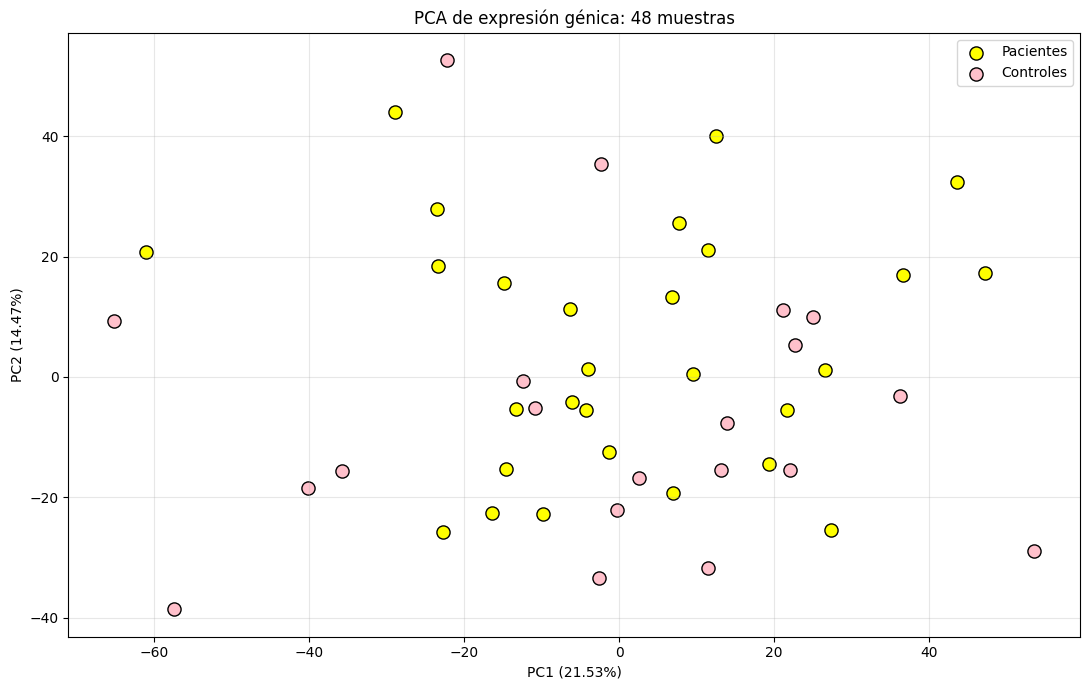

In [47]:
#Grafico de PCA de las 48 muestras

#Creo la figura
plt.figure(figsize=(11, 7))

#Grafico de los pacientes
plt.scatter(
    df_pca_original[df_pca_original["Grupo"] == "Paciente"]["PC1"],
    df_pca_original[df_pca_original["Grupo"] == "Paciente"]["PC2"],
    color="yellow",
    edgecolors="black",
    label="Pacientes",
    s=90
)

#Grafico de los controles
plt.scatter(
    df_pca_original[df_pca_original["Grupo"] == "Control"]["PC1"],
    df_pca_original[df_pca_original["Grupo"] == "Control"]["PC2"],
    color="pink",
    edgecolors="black",
    label="Controles",
    s=90
)

#Ejes con nombre y porcentajes de varianza
plt.xlabel(f"PC1 ({pca_original.explained_variance_ratio_[0] * 100:.2f}%)")
plt.ylabel(f"PC2 ({pca_original.explained_variance_ratio_[1] * 100:.2f}%)")

#Titulo, referencias, cuadricula
plt.title("PCA de expresión génica: 48 muestras")
plt.legend()
plt.grid(alpha=0.3)

#Muestro el grafico
plt.tight_layout()
plt.show()


En el grafico se puede ver una dispersion considerable de muestras, con paciente sy controles distribuidos en distintas regiones de ambos componentes principales.

No se ve una separacion clara entre los dos grupos ya que existe una superposicion importante entre pacientes y controles.

Aun considerando 48 muestras los dos primeros componentes principales no permiten distinguir claramente a los individuos segun su condicion experimental.

In [48]:
#Aplicacion de K-means
#Se utiliza k=2, es decir, 2 grupos
#K-means solo analiza los valores de expresion para formar dos grupos

from sklearn.cluster import KMeans

#Modelo para los dos grupos
kmeans_original = KMeans(
    n_clusters=2,
    random_state=0,
    n_init=10
)

#Aplico K-means a la matriz original
grupos_kmeans_original = kmeans_original.fit_predict(matriz_pca_original)

#Mostrar grupo asignado a cada individuo
for muestra, grupo in zip(matriz_pca_original.index, grupos_kmeans_original):
    print(muestra, "-> Grupo", grupo)


Control3 -> Grupo 1
Control11 -> Grupo 0
Control4 -> Grupo 0
Control5 -> Grupo 1
Control1 -> Grupo 1
Ticpatient17 -> Grupo 0
Ticpatient8 -> Grupo 0
Ticpatient22 -> Grupo 0
Ticpatient26 -> Grupo 1
Control12 -> Grupo 1
Ticpatient1 -> Grupo 1
Control19 -> Grupo 0
Ticpatient14 -> Grupo 0
Control7 -> Grupo 0
Control6 -> Grupo 1
Ticpatient28 -> Grupo 1
Ticpatient24 -> Grupo 0
Ticpatient2 -> Grupo 1
Control10 -> Grupo 1
Ticpatient6 -> Grupo 1
Ticpatient3 -> Grupo 1
Control9 -> Grupo 0
Ticpatient21 -> Grupo 0
Control14 -> Grupo 1
Control16 -> Grupo 0
Ticpatient18 -> Grupo 0
Ticpatient11 -> Grupo 1
Ticpatient15 -> Grupo 0
Control2 -> Grupo 1
Ticpatient9 -> Grupo 1
Control18 -> Grupo 1
Ticpatient19 -> Grupo 1
Ticpatient25 -> Grupo 0
Ticpatient4 -> Grupo 1
Ticpatient23 -> Grupo 0
Ticpatient20 -> Grupo 1
Control20 -> Grupo 0
Ticpatient12 -> Grupo 0
Ticpatient7 -> Grupo 1
Control17 -> Grupo 0
Ticpatient16 -> Grupo 0
Control15 -> Grupo 0
Ticpatient10 -> Grupo 1
Control13 -> Grupo 0
Ticpatient27 -> G

Se aplicó K-means con K = 2 a los perfiles de expresión de los 48 individuos, obteniéndose dos agrupamientos de 24 muestras cada uno.

Los grupos se formaron según las similitudes de expresión génica, sin utilizar previamente la clasificación de pacientes y controles.

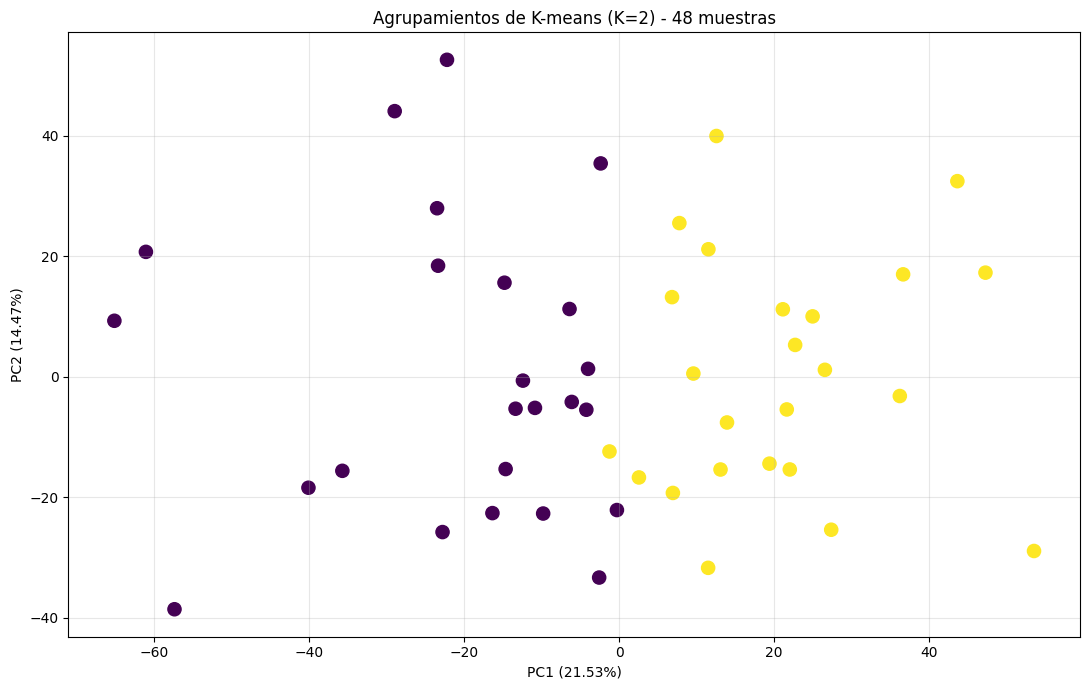

In [49]:
#Grafico de agrupamiento de K-means para las 48 muestras

#Creo la figura
plt.figure(figsize=(11, 7))

#Dibujo los individuos segun el grupo asignado por K-means
plt.scatter(
    componentes_original[:, 0],   #Coordenadas de PC1
    componentes_original[:, 1],   #Coordenadas de PC2
    c=grupos_kmeans_original,     #Colores segun los grupos de K-means
    cmap="viridis",
    s=90
)

#Ejes
plt.xlabel(f"PC1 ({pca_original.explained_variance_ratio_[0] * 100:.2f}%)")
plt.ylabel(f"PC2 ({pca_original.explained_variance_ratio_[1] * 100:.2f}%)")

#Titulo y cuadricula
plt.title("Agrupamientos de K-means (K=2) - 48 muestras")
plt.grid(alpha=0.3)

#Muestro el grafico
plt.tight_layout()
plt.show()


En el gráfico se observan dos agrupamientos diferenciados principalmente sobre el primer componente principal (PC1).

Sin embargo, estos agrupamientos no necesariamente corresponden a pacientes y controles, ya que K-means clasificó las muestras según sus perfiles de expresión y no según su condición experimental.

In [50]:
#Comparacion de los grupos de K-means con pacientes y controles

#Agrego el grupo de K-means a la tabla de PCA
df_pca_original["K-means"] = grupos_kmeans_original

#Cuento cuantos pacientes y controles quedaron en cada grupo
tabla_grupos_original = pd.crosstab(
    df_pca_original["Grupo"],
    df_pca_original["K-means"]
)

#Muestro la tabla
print("Cantidad de pacientes y controles por grupo de K-means:")
display(tabla_grupos_original)


Cantidad de pacientes y controles por grupo de K-means:


K-means,0,1
Grupo,,
Control,10,10
Paciente,14,14


Al comparar los agrupamientos obtenidos con la clasificación experimental, se observó que cada grupo contiene 14 pacientes y 10 controles.

Por lo tanto, K-means no logró separar a los pacientes de los controles, ya que ambos grupos presentan exactamente la misma proporción de individuos de cada condición.

In [51]:
#Calculo distancias entre los 48 individuos

#Importo herramienta
from sklearn.metrics import pairwise_distances

#Calculo distancias
distancias_original = pairwise_distances(
    matriz_pca_original,
    metric="euclidean"
)

#Tabla con resultados
df_distancias_original = pd.DataFrame(
    distancias_original,
    index=matriz_pca_original.index,
    columns=matriz_pca_original.index
)

#Muestro las dimensiones y las primeras filas
print("Dimensiones:", df_distancias_original.shape)
display(df_distancias_original.iloc[:5, :5].round(2))


Dimensiones: (48, 48)


,Control3,Control11,Control4,Control5,Control1
Control3,0.00,92.21,94.55,58.20,69.42
Control11,92.21,0.00,70.86,91.81,80.24
Control4,94.55,70.86,0.00,100.42,85.19
Control5,58.20,91.81,100.42,0.00,62.56
Control1,69.42,80.24,85.19,62.56,0.00


Se calcularon las distancias euclidianas entre los perfiles de expresión de los 48 individuos, obteniéndose una matriz de 48 × 48.

Las distancias menores indican perfiles de expresión más similares, mientras que las mayores indican diferencias más grandes.

Por ejemplo, Control3 y Control5 presentan una distancia de 58,20, menor que la distancia entre Control3 y Control4 (94,55), lo que indica una mayor similitud entre los dos primeros controles según esta medida.

**Conclusion general PCA**

En el análisis de las 6 muestras se observó una separación parcial entre pacientes y controles, principalmente sobre PC2, aunque algunos individuos presentaron perfiles similares.

En cambio, al analizar las 48 muestras, se observó una mayor dispersión y superposición entre pacientes y controles, sin una separación clara según su condición.

Estos resultados sugieren que la separación observada inicialmente no se mantiene de manera evidente en el conjunto completo. Sin embargo, las diferencias también pueden estar relacionadas con los distintos procesamientos y conjuntos de genes utilizados.

**Conclusion general K-means**

Al aplicar K-means sobre la matriz de 6 muestras no se observo una separacion completa, luego al repetir el analisis con la matriz de 48 muestras se obtivieron dos agrupamientos pero nuevamente no se permiten distinguir a los pacientes de controles segun su condicion experimental.

Ambos analisis muetsrasn que K-means identifica similitudes entre los perfiles de expresion genica pero no logra una clasificacion clara entre pacientes y controles sanos.

#Conclusion del proyecto

En este trabajo se realizo un analisis exploratorio de datos transcriptomicos de pacientes con trastornos de tics, incluido el sindrome de tourette y controles sanos, a partir de dos matrices de expresion genica obtenidas mediante diferentes procedimientos bioinformaticos.

La comparacion inical permitio identificar genes compartidos y encontrar una concordancia en sus patrones de abundancia, lo que indica que el procedimiento realizado en la primera etapa del proyecto logro reproducir parcialmente los resultados de cuantificacion del estudio original.
De todas formas, esta similitud no implica que los valores de expresion sean identicos ni que ambos metodos de procesamiento permitan obtener las mismas conclusiones.

Posteriormente, investigo si los perfiles de expresion genica permitian diferenciar a los pacientes de los controles, y si bien se pudieron observar algunos patrones de agrupamiento, estos no fueron suficientes para establecer una separacion clara de los grupos experimentales.

Estos resultados muestran que este tipo de metodos exploratorios no fueron suficientes para identificar una clasificacion clara segun la condicion clinica.

En articulo original se identificaron genes diferencialmente expresados y alteraciones en procesos biologicos relacionados principalmenre con la regulacion de la cromatina, la respuesta inmunitaria, entre otros. Estos hallazgos sugieren que las diferencias entre pacientes y controles podrian manifestarse en genes y vias biologicas especificas sin necesariamente producir una separacion global visible en los graficos propuestos.

Se puede decir que como continuacion del proyecto seria posible estudiar los genes diferencialmente expresado y analizar su participacion en estos procesos biologicos, para asi comprender mejor que mecanismos moleculares podrian estar relacionados con los trastornos de tics.

Finalmente, considerando que los mecanismos del sindrome de tourette todavia no se comprenden completamente y que los estudios transcriptomicos disponibles son limitados, en este trabajo los resultados obtenidos muestran tanto la posibilidad de las herramientas bioinformaticas como la necesidad de hacer investigaciones mas profundas para comprender mejor las bases biologicas de estos trastornos.
